<a href="https://colab.research.google.com/github/andresuribe1987-code/Conectatel-analysis/blob/main/S7_Version_Estudiante_Project_ConnectaTel_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

¡Hola Andres Alberto! Espero estés bien.

Mi nombre es **Gina Buvoli**. Un gusto conocerte, seré tu revisora en este proyecto.

A continuación, te comparto un poco sobre la modalidad de revisión que vamos a usar:

Cuando encuentre un error por primera vez, simplemente lo señalaré y dejaré que lo detectes y corrijas por tu cuenta. Además, a lo largo del proyecto iré haciendo algunas observaciones para mejorar tu código, así como comentarios sobre tus conclusiones o percepciones sobre el tema.

Si en algún momento no logras resolver la tarea, en la siguiente iteración te daré una pista más precisa, junto con algunos ejemplos prácticos. También estoy abierta a responder cualquier duda que tengas.

Encontrarás mis comentarios a continuación: por favor, no los muevas, modifiques ni elimines.

---

### Formato de Comentarios

Revisaré cuidadosamente cada implementación en tu notebook para asegurar que cumpla con los requisitos y te daré comentarios de acuerdo al siguiente formato:

<div class="alert alert-block alert-success">

<b>Comentario de la revisora [#° iteración]</b> <a class="tocSkip"></a><br>

<b>Éxito ✅</b><br>

¡Excelente trabajo! Esta parte está bien implementada y contribuye significativamente al análisis. Continúa aplicando estas buenas prácticas en futuras secciones.

</div>

<div class="alert alert-block alert-warning">

<b>Comentario de la revisora [#° iteración]</b> <a class="tocSkip"></a><br>

<b>Atención ⚠️</b><br>

El código es correcto, pero hay una recomendación de mejora. No bloquea la aprobación, pero vale la pena ajustarlo.

</div>

<div class="alert alert-block alert-danger">

<b>Comentario de la revisora [#° iteración]</b> <a class="tocSkip"></a><br>

<b>A resolver 🔴</b><br>

Aquí hay un error que es necesario corregir para aprobar. Por favor revisa este punto antes de volver a enviar.

</div>

---

En cada revisión recibirás un **Comentario General** que resume los aspectos positivos, las áreas de mejora y los próximos pasos.

También puedes responderme copiando el siguiente bloque si tienes alguna duda:

<div class="alert alert-block alert-info">

<b>Respuesta del estudiante [#° iteración]</b> <a class="tocSkip"></a>

Aquí puedes escribir tu respuesta o pregunta.

</div>

**¡Empecemos!** 🚀


<div class="alert alert-block alert-danger">
<b>Review General. (Iteración 1)</b> <a class="tocSkip"></a>

¡Hola Andres Alberto!

Tu proyecto está muy bien encaminado. Destaco especialmente la claridad con la que documentaste la limpieza de datos, el análisis de los nulos MAR en <code>duration</code> y <code>length</code>, la segmentación de clientes y el insight ejecutivo, donde conectas los resultados con recomendaciones concretas para ConnectaTel.

Antes de aprobarlo necesitamos ajustar un punto obligatorio:

1. En la sección de outliers, debes implementar realmente el cálculo de los límites mediante el método IQR. Actualmente defines las columnas y luego revisas <code>describe()</code>, pero los límites que mencionas en las conclusiones no se calculan en el código del notebook.

También encontrarás recomendaciones amarillas para fortalecer la función reutilizable de detección de valores inválidos, conservar correctamente los ceros después del <code>left merge</code> y alinear la estructura real del repositorio con lo descrito en el README.

<b>Vas por muy buen camino, Andres Alberto.</b> La mayor parte del análisis está completa y bien razonada; solo necesitas cerrar correctamente el cálculo de IQR para que el flujo quede reproducible de principio a fin. Tienes una buena base y estás muy cerca de tener el proyecto listo. ¡Mucho ánimo para la siguiente iteración!

Saludos,  
Gina Buvoli
</div>


# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [ ]:

# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

(plans.head())
(users.head())
(usage.head())


,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


In [ ]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [ ]:
# mostrar las primeras 5 filas de plans
(plans.head())

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [ ]:
# mostrar las primeras 5 filas de users
(users.head())

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [ ]:
# mostrar las primeras 5 filas de usage
(usage.head())

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [ ]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

# resumen de columnas, tipos de datos y valores no nulos
plans.info()
print()
users.info()
print()
usage.info()


plans (2, 8)
users (4000, 8)
usage (40000, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object


In [ ]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [ ]:

# inspección de users con .info()
users.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [ ]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


<div class="alert alert-block alert-success">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a><br>
<b>Éxito ✅</b><br>
Muy buena carga y exploración inicial. Importas las librerías necesarias, cargas los tres datasets y revisas su estructura con <code>head()</code>, <code>shape</code> e <code>info()</code>. Esto deja una base clara para continuar con el análisis.
</div>


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [ ]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())

# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


In [ ]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.
 -
### Diagnóstico de valores nulos
**users**
- `city` (11.7%, entre 5% y 30%): se deja como nulo, porque no se puede deducir la ciudad y no es clave para el análisis de uso.
- `churn_date` (88.4%, más del 80-90%): no se elimina ni se imputa, porque el nulo significa que el cliente sigue activo y sirve para marcar el churn.
- Las demás columnas no tienen nulos, así que no requieren acción.

**usage**
- `duration` (55.2%): se deja como nulo, porque probablemente solo falta en los mensajes y se confirma en el paso 3.2.
- `length` (44.7%): se deja como nulo, porque probablemente solo falta en las llamadas y se confirma en el paso 3.2.
- `date` (0.125%, menos del 5%): se deja como nulo y se excluye al analizar por año, porque son pocas filas y no se puede inferir la fecha.
- `id`, `user_id` y `type` no tienen nulos, así que no requieren acción.

 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?
-
### Diagnóstico de valores nulos
**users (4,000 filas)**
- `city`: 469 nulos (11.7%). Acción: dejar como nulo (o etiquetar "desconocida"). Está en el rango 5%-30%, no es una variable crítica para el análisis de uso y no hay una imputación razonable de una ciudad.
- `churn_date`: 3,534 nulos (88.4%). Acción: no eliminar ni imputar. El hint sugiere ignorar columnas con más de 80-90% de nulos, pero aquí el nulo tiene significado: el cliente no se ha dado de baja. Se usará para crear un indicador de churn.
- Resto de columnas (`user_id`, `first_name`, `last_name`, `age`, `reg_date`, `plan`): sin nulos, no requieren acción.

**usage (40,000 filas)**
- `duration`: 22,076 nulos (55.2%). Acción: dejar como nulo. Probablemente faltan en los mensajes, porque un mensaje no tiene duración; se confirma en el paso 3.2 revisando si depende de `type`.
- `length`: 17,896 nulos (44.7%). Acción: dejar como nulo. Probablemente faltan en las llamadas, porque una llamada no tiene longitud (se confirma en el paso 3.2).
- `date`: 50 nulos (0.125%). Acción: dejar como nulo y excluir esas filas al analizar por año. Es menos de 5%, afecta a muy pocos registros y no se puede deducir la fecha.
- Resto de columnas (`id`, `user_id`, `type`): sin nulos, no requieren acción.


### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [ ]:
# explorar columnas numéricas de users
users[['user_id', 'age']].describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` ... Haz doble clic en este bloque y escribe qué ves.
- La columna `age` ...

* La columna `user_id`: tiene 4,000 valores únicos y consecutivos, de 10,000 a 13,999, uno por cliente. Es un identificador, así que su media y sus cuartiles no tienen significado analítico. No presenta sentinels ni requiere limpieza.
  
* La columna `age`: va de -999 a 79, con media de 33.7 y mediana de 47. El valor -999 es un sentinel, no una edad real, y arrastra la media por debajo de la mediana y dispara la desviación estándar (123.2). Sin él, el rango parece razonable (el 25% está en 32 años y el máximo es 79). Acción: reemplazar -999 por la mediana en el paso 3.1.

In [ ]:
# explorar columnas numéricas de usage
usage[['id', 'user_id', 'duration', 'length']].describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
- Las columnas ...

* Las columnas `id` y `user_id`: `id` va de 1 a 40,000 (un valor por registro de uso) y `user_id` va de 10,000 a 13,999, el mismo rango que en `users`, así que las tablas se podrán unir. Son identificadores, por lo que su media y sus cuartiles no tienen significado analítico. No presentan sentinels ni requieren limpieza.
  
* Las columnas `duration` y `length`: no tienen valores negativos ni sentinels tipo -999. `duration` tiene 17,924 valores con media de 5.2, mediana de 3.5 y máximo de 120. `length` tiene 22,104 valores con media de 52.1, mediana de 50 y máximo de 1,490. Las dos distribuciones están sesgadas a la derecha: el 75% de las llamadas dura 6.99 o menos y el 75% de los mensajes mide 64 o menos, pero los máximos son muy superiores. El mínimo de 0 en ambas puede ser una llamada sin respuesta o un mensaje vacío. Acción: no reemplazar nada y revisar los valores extremos como posibles outliers en el paso 5.2.

In [ ]:

# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

for col in columnas_user:
    print(col)
    print(users[col].value_counts(dropna=False))
    print()



city
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

plan
Basico     2595
Premium    1405
Name: plan, dtype: int64





* La columna `city`: tiene 7 ciudades (Bogotá 808, CDMX 730, Medellín 616, GDL 450, Cali 424 y MTY 407), con 469 nulos y 96 valores `"?"`. El `"?"` es un sentinel, no una ciudad real. Acción: reemplazar `"?"` por nulo en el paso 3.1, con lo que los nulos de `city` pasarán de 469 a 565 (14.1% de las 4,000 filas), y dejarlos como nulos porque no hay forma razonable de deducir la ciudad.
  
* La columna `plan`: solo tiene dos valores, Basico (2,595, 64.9%) y Premium (1,405, 35.1%), sin nulos, sin variantes de escritura y sin sentinels. No requiere limpieza.

In [ ]:
# explorar columna categórica de usage
usage['type'].value_counts(dropna=False)

text    22092
call    17908
Name: type, dtype: int64

* La columna `type`: solo tiene dos valores, `text` (22,092, 55.2%) y `call` (17,908, 44.8%), sin nulos, sin variantes de escritura y sin sentinels. Suman 40,000, igual que el número de filas. No requiere limpieza.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso.

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?
### Diagnóstico de valores inválidos y sentinels

**¿En qué columnas encontré valores inválidos o sentinels?**

- `age` (users): el valor -999 es un sentinel, no una edad real. Se nota porque el mínimo es -999, la media (33.7) queda muy por debajo de la mediana (47) y la desviación estándar se dispara (123.2). Sin ese valor, el rango es razonable (hasta 79 años).
- `city` (users): 96 valores `"?"`, que no son una ciudad real. Se suman a los 469 nulos que ya había (565 en total, 14.1%).
  
- `user_id` (users), `id` y `user_id` (usage), `duration`, `length`, `plan` y `type`: no presentan sentinels. `plan` solo tiene Basico y Premium, `type` solo tiene `text` y `call`, y `duration` y `length` no tienen valores negativos, aunque hay valores en 0 y máximos extremos que se revisarán como outliers.

**¿Qué acción tomaría?**
- `age`: reemplazar -999 por la mediana (paso 3.1), porque es una variable numérica y la mediana no se distorsiona con valores extremos.
-
- `city`: reemplazar `"?"` por nulo (paso 3.1) y dejarlos como nulos, porque no hay forma razonable de deducir la ciudad.
-
- `duration` y `length`: no reemplazar nada; revisar los valores extremos como posibles outliers en el paso 5.2.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [ ]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [ ]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')


In [ ]:
# Revisar los años presentes en `reg_date` de users
print(users['reg_date'].dt.year.value_counts().sort_index())

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


En `reg_date`, los registros se reparten de forma muy pareja entre 2022 (1,314), 2023 (1,316) y 2024 (1,330), pero aparecen 40 registros con año 2026. Como los datos llegan hasta 2024, esas fechas son imposibles (un año que aún no ha transcurrido) y se tratan como errores de captura. Representan el 1.0% de las 4,000 filas. Acción: marcarlas como nulas (`NaT`) en el paso 3.1, en lugar de eliminar a los clientes, porque el resto de sus datos puede servir para el análisis.

In [ ]:
# Revisar los años presentes en `date` de usage
print(usage['date'].dt.year.value_counts().sort_index())


2024.0    39950
Name: date, dtype: int64


En `date`, los 39,950 registros con fecha son todos del año 2024, así que no aparecen años futuros, negativos ni antiguos. Los 50 registros restantes son los nulos ya vistos en el paso 2.1 (0.125%). Todas las fechas válidas caen dentro del periodo con datos hasta 2024, y el análisis de uso se basará en ellas. Acción: no hay fechas fuera de rango que corregir; los 50 nulos se dejan como nulos y se excluyen al analizar por fecha.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?


### Diagnóstico de fechas fuera de rango

**¿Aparecen años imposibles?**
- Sí, en `reg_date` de users: 40 registros con año 2026 (1.0% de las 4,000 filas). Como los datos llegan hasta 2024, es un año que aún no había transcurrido al guardar los datos, así que son errores de captura. El resto se reparte de forma pareja entre 2022 (1,314), 2023 (1,316) y 2024 (1,330).
- No en `date` de usage: los 39,950 registros con fecha son todos de 2024, y no aparecen años futuros, negativos ni muy antiguos. Los 50 restantes son nulos ya vistos.

**¿Qué haría con ellas?**
- `reg_date`: marcar las 40 fechas de 2026 como nulas (`NaT`) en el paso 3.1, en lugar de eliminar los clientes, porque el resto de sus datos sirve para el análisis. Quedarían 40 nulos nuevos (1.0%), un caso simple según el hint.
- `date`: no hay fechas fuera de rango que corregir. Los 50 nulos se dejan como nulos y se excluyen al analizar por fecha.

<div class="alert alert-block alert-warning">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a><br>
<b>Atención ⚠️</b><br>
La identificación de sentinels y fechas fuera de rango está bien desarrollada: detectas <code>-999</code> en <code>age</code>, <code>"?"</code> en <code>city</code> y los registros de 2026 en <code>reg_date</code>. Como mejora menor, completa también la revisión explícita de nulos en <code>plans</code> y considera encapsular la búsqueda de valores inválidos en una función reutilizable <code>valores_invalidos(df, columnas)</code>. Esto hará tu proceso más consistente y fácil de reutilizar.
</div>


---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [ ]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [ ]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print(users['city'].isna().sum())
print(users['city'].value_counts(dropna=False))

565
Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64


In [ ]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
print(users['reg_date'].isna().sum())
print(users['reg_date'].dt.year.value_counts().sort_index())

40
2022.0    1314
2023.0    1316
2024.0    1330
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [ ]:
# Verificación MAR en usage (Missing At Random) para duration
print(usage['duration'].isna().groupby(usage['type']).mean())


type
call    0.000000
text    0.999276
Name: duration, dtype: float64


In [ ]:
# Verificación MAR en usage (Missing At Random) para length
print(usage['length'].isna().groupby(usage['type']).mean())


type
call    0.99933
text    0.00000
Name: length, dtype: float64


### Diagnóstico de nulos en `duration` y `length`

- `duration` tiene 22,076 nulos (55.2%) y `length` tiene 17,896 (44.7%). Al agrupar por `type`, `duration` falta en [X]% de los mensajes (`text`) y en [Y]% de las llamadas (`call`), mientras que `length` falta en [X]% de las llamadas y en [Y]% de los mensajes.
  
- Los nulos dependen de la columna `type`, así que son MAR (Missing At Random): un mensaje no tiene duración y una llamada no tiene longitud. No son datos perdidos, sino campos que no aplican al tipo de registro.

  
- Decisión: dejarlos como nulos. Imputarlos (con media o mediana) crearía duraciones para mensajes y longitudes para llamadas que no existen, y distorsionaría las estadísticas de uso. Para cada análisis se filtra por el tipo correspondiente (`call` para `duration`, `text` para `length`).

<div class="alert alert-block alert-success">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a><br>
<b>Éxito ✅</b><br>
Muy buen criterio en la limpieza. Corriges los sentinels sin eliminar usuarios, marcas las fechas futuras como <code>NaT</code> y demuestras que los nulos de <code>duration</code> y <code>length</code> dependen del tipo de evento. La decisión de mantenerlos como nulos está correctamente justificada porque representan campos que no aplican.
</div>


---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [ ]:

# 1. Crear columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int)
usage["is_call"] = (usage["type"] == "call").astype(int)

# 2. Agrupar información por usuario
usage_agg = (
    usage.groupby("user_id")
    [["is_text", "is_call", "duration"]]
    .sum()
    .reset_index()
)

# 3. Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada"
})

# 4. Combinar con el dataset de usuarios
user_profile = users.merge(
    usage_agg,
    on="user_id",
    how="left"
)

# 5. Reemplazar valores NaN por cero
columnas = [
    "cant_mensajes",
    "cant_llamadas",
    "cant_minutos_llamada"
]

user_profile[columnas] = user_profile[columnas].fillna(0)

# 6. Observar resultado
user_profile.head(5)


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


In [ ]:
# Renombrar columnas

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [ ]:
# Resumen estadístico de las columnas numéricas
user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].describe()


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [ ]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True) * 100


Basico     64.875
Premium    35.125
Name: plan, dtype: float64

<div class="alert alert-block alert-warning">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a><br>
<b>Atención ⚠️</b><br>
La agregación por <code>user_id</code> está bien construida y las tres métricas quedan correctamente nombradas. Sin embargo, observa que primero completas con cero las métricas de usuarios sin actividad y luego vuelves a crear <code>user_profile</code> con otro <code>merge</code>; por eso el resumen vuelve a mostrar 3,999 valores en lugar de 4,000. Como mejora, conserva el DataFrame ya completado o vuelve a aplicar el tratamiento de nulos después del último <code>merge</code>. Esto evita que un usuario sin actividad termine afectando la segmentación posterior.
</div>


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)

**Hint**  
Para cada histograma,
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

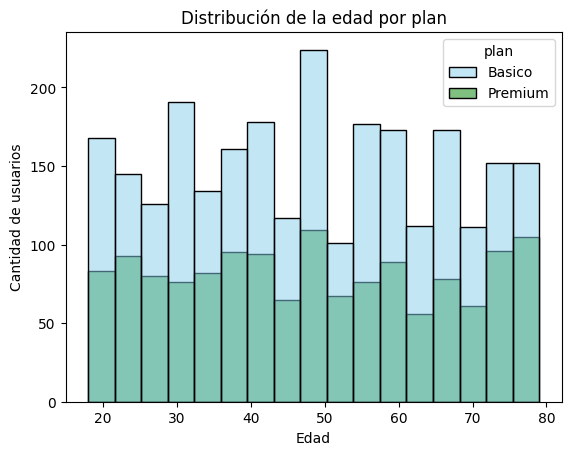

In [ ]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue', 'green'])
plt.title('Distribución de la edad por plan')
plt.xlabel('Edad')
plt.ylabel('Cantidad de usuarios')
plt.show()


  💡Insights:
- Distribución: aproximadamente uniforme (plana), sin sesgo marcado a la derecha ni a la izquierda. Las edades van de unos 18 a 79 años y se reparten de forma bastante pareja, con entre ~100 y ~225 usuarios por rango.
- Por plan: Basico supera a Premium en prácticamente todos los rangos de edad (aprox. el doble, coherente con el 64.9% frente al 35.1% de usuarios), pero la forma de las dos distribuciones es parecida. No existe algún patrón claro de edad según el plan.
- Hay un pico en torno a los 48-50 años (~224 usuarios en Basico y ~109 en Premium), bastante por encima de los rangos vecinos. Probablemente corresponde a los usuarios con -999 que se reemplazaron por la mediana en el paso 3.1, y no a un patrón real de la edad.


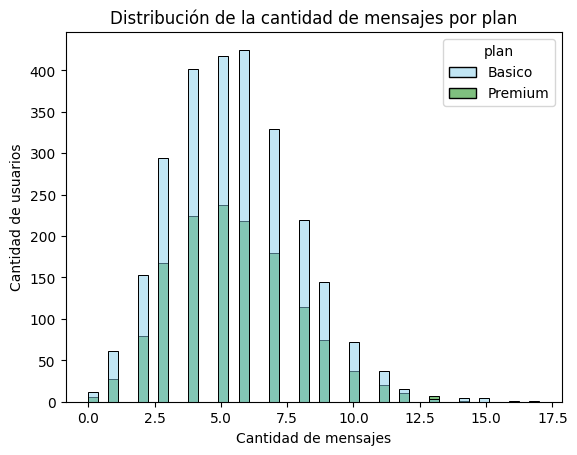

In [ ]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'])
plt.title('Distribución de la cantidad de mensajes por plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.show()


💡💡Insights:
- Distribución: casi simétrica en forma de campana, con una ligera cola hacia la derecha (sesgo a la derecha leve). La mayoría de los usuarios envía entre 3 y 7 mensajes, con el pico en 5 y 6 (unos 420 usuarios en total). Los valores van de 0 a unos 17, y a partir de 10 mensajes quedan muy pocos usuarios.
- Por plan: Basico y Premium tienen la misma forma y el mismo pico (5 a 6 mensajes), y Basico es más alto en todas las barras por tener casi el doble de usuarios (64.9% frente a 35.1%). No existe algún patrón: los usuarios Premium no envían más mensajes que los Basico.
- Los usuarios con 12 o más mensajes son muy pocos, así que son candidatos a revisar como posibles outliers en el paso 5.2.

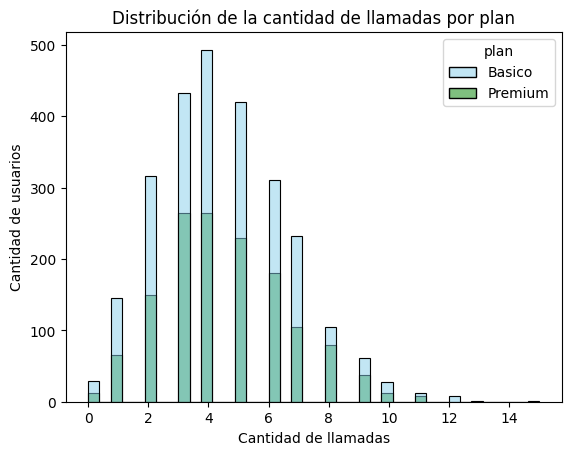

In [ ]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'])
plt.title('Distribución de la cantidad de llamadas por plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()


💡Insights:
- Distribución: sesgada a la derecha. La mayoría de los usuarios hace entre 2 y 6 llamadas, con el pico en 4 (unos 490 usuarios en total) y una cola que se extiende hasta unas 15 llamadas, con muy pocos usuarios más allá de 10.
- Por plan: Basico y Premium tienen la misma forma y el mismo pico (3 a 4 llamadas). Basico es más alto en todas las barras por tener casi el doble de usuarios (64.9% frente a 35.1%). No existe algún patrón: los usuarios Premium no hacen más llamadas que los Basico.
- Los usuarios con más de 10 llamadas son muy pocos, así que son candidatos a revisar como posibles outliers en el paso 5.2.

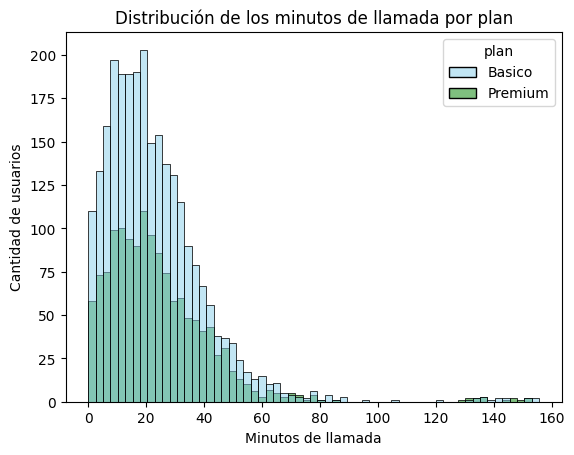

In [ ]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue', 'green'])
plt.title('Distribución de los minutos de llamada por plan')
plt.xlabel('Minutos de llamada')
plt.ylabel('Cantidad de usuarios')
plt.show()


💡💡 **Insights:**

- La mayor concentración de usuarios de ambos planes se encuentra aproximadamente entre los 10 y 35 minutos de llamadas.
- El plan Básico presenta una mayor cantidad de usuarios en prácticamente todos los intervalos de consumo.
- Ambos planes muestran una distribución asimétrica hacia la derecha (sesgo positivo), lo que indica que la mayoría de los usuarios consume pocos minutos, mientras que una minoría registra consumos elevados.
- Se observan algunos valores extremos (outliers) por encima de los 120 minutos, que podrían corresponder a usuarios con un consumo de llamadas considerablemente superior al promedio.
- Aunque el plan Básico tiene mayores frecuencias absolutas, esto no significa necesariamente que sus usuarios consuman más minutos individualmente, ya que es necesario considerar la cantidad total de usuarios de cada plan.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

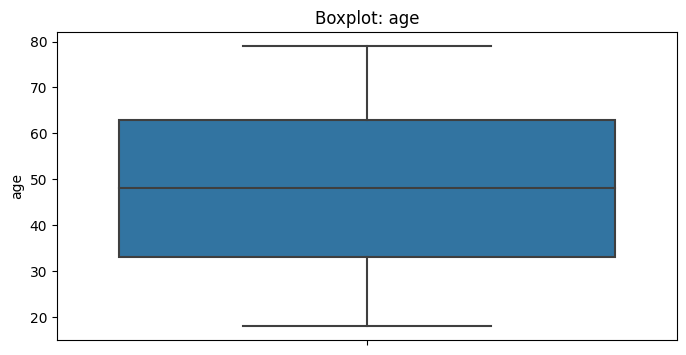

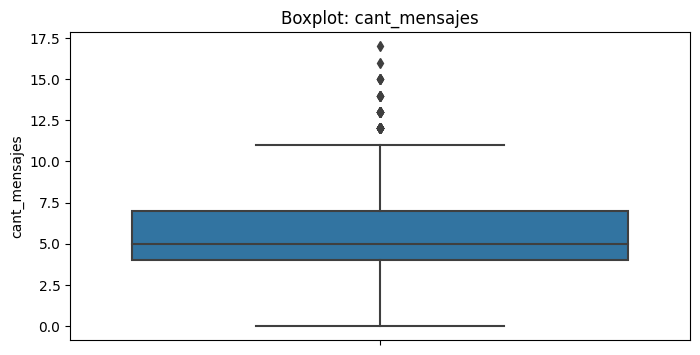

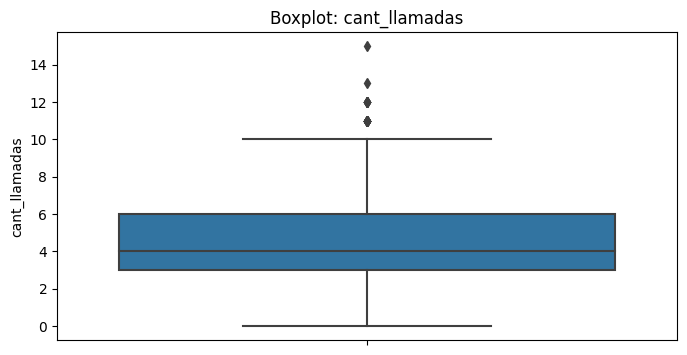

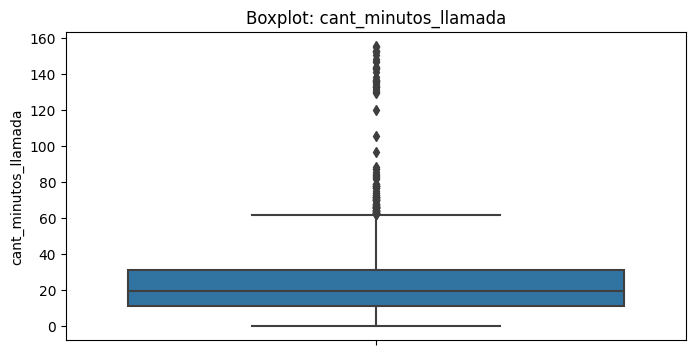

In [ ]:

# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=user_profile, y=col)
    plt.title(f'Boxplot: {col}')
    plt.ylabel(col)
    plt.show()


💡Insights:

Age: No presenta valores atípicos (outliers). Las edades se distribuyen aproximadamente entre 18 y 79 años, con una mediana de 48 años.

cant_mensajes: Presenta valores atípicos por encima de 11 mensajes, llegando aproximadamente hasta 17. La mayoría de los registros se concentra entre 4 y 7 mensajes.

cant_llamadas: Presenta valores atípicos superiores a 10 llamadas, llegando aproximadamente hasta 15. La mayor concentración se encuentra entre 3 y 6 llamadas.

cant_minutos_llamada: Presenta numerosos valores atípicos por encima de 62 minutos, llegando aproximadamente hasta 156 minutos. La mayoría de los registros se concentra entre 11 y 32 minutos, con una mediana cercana a 20 minutos.

In [ ]:


# Calcular límites con el método IQR
columnas_limites = [
    'age',
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]


In [ ]:
# Calcular Q1, Q3, IQR y límites para cada variable

for columna in columnas_limites:

    Q1 = user_profile[columna].quantile(0.25)
    Q3 = user_profile[columna].quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = user_profile[
        (user_profile[columna] < limite_inferior) |
        (user_profile[columna] > limite_superior)
    ]

    print(f"\nVariable: {columna}")
    print(f"Q1: {Q1:.2f}")
    print(f"Q3: {Q3:.2f}")
    print(f"IQR: {IQR:.2f}")
    print(f"Límite inferior: {limite_inferior:.2f}")
    print(f"Límite superior: {limite_superior:.2f}")
    print(f"Máximo observado: {user_profile[columna].max():.2f}")
    print(f"Cantidad de outliers: {len(outliers)}")



Variable: age
Q1: 33.00
Q3: 63.00
IQR: 30.00
Límite inferior: -12.00
Límite superior: 108.00
Máximo observado: 79.00
Cantidad de outliers: 0

Variable: cant_mensajes
Q1: 4.00
Q3: 7.00
IQR: 3.00
Límite inferior: -0.50
Límite superior: 11.50
Máximo observado: 17.00
Cantidad de outliers: 46

Variable: cant_llamadas
Q1: 3.00
Q3: 6.00
IQR: 3.00
Límite inferior: -1.50
Límite superior: 10.50
Máximo observado: 15.00
Cantidad de outliers: 30

Variable: cant_minutos_llamada
Q1: 11.12
Q3: 31.41
IQR: 20.30
Límite inferior: -19.32
Límite superior: 61.86
Máximo observado: 155.69
Cantidad de outliers: 109


In [ ]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


 ### 💡 Insights y decisiones sobre los valores atípicos

**- cant_mensajes:** Mantener los outliers. Se identificaron 46 registros que superan el límite superior establecido mediante el método IQR (11.5 mensajes), con un valor máximo observado de 17 mensajes. Estos valores pueden representar usuarios con una actividad de comunicación superior al promedio. Su eliminación podría ocasionar una pérdida de información relevante para identificar segmentos de clientes con mayor intensidad de uso del servicio. Por lo tanto, se conservan al no existir evidencia suficiente de que correspondan a errores en los datos.

**- cant_llamadas:** Mantener los outliers. Se identificaron 30 registros que superan el límite superior de 10.5 llamadas, con un máximo observado de 15 llamadas. Estas observaciones pueden corresponder a usuarios que realizan llamadas con mayor frecuencia y representan patrones válidos de utilización del servicio. Conservarlos permite mantener la diversidad del comportamiento de los clientes y evitar sesgos en el análisis del consumo.

**- cant_minutos_llamada:** Mantener los outliers. Se identificaron 109 registros que superan el límite superior de 61.86 minutos, alcanzando un máximo observado de 155.69 minutos. Aunque estos valores se encuentran considerablemente alejados del rango intercuartílico, pueden representar usuarios con una duración acumulada de llamadas elevada. Eliminarlos podría distorsionar el análisis del consumo real y ocasionar la pérdida de información sobre los clientes de mayor utilización. Se conservan provisionalmente, considerando que no se ha identificado evidencia de errores de registro.

**- age:** No se identificaron valores atípicos mediante el método IQR. El valor máximo observado fue de 79 años, mientras que el límite superior calculado fue de 108 años. Por tanto, se conservan todos los registros de esta variable.

<div class="alert alert-block alert-danger">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a><br>
<b>A resolver 🔴</b><br>
Los histogramas, boxplots y la interpretación de los valores extremos están bien planteados. El punto pendiente es el cálculo del método IQR: en la celda correspondiente solo defines la lista de columnas y luego utilizas <code>describe()</code>, pero no calculas <code>Q1</code>, <code>Q3</code>, el <code>IQR</code> ni los límites inferior y superior que posteriormente mencionas en tus conclusiones.

Para la siguiente iteración, revisa esta sección paso a paso:
<ol>
<li>Calcula el primer cuartil (<code>Q1</code>) y el tercer cuartil (<code>Q3</code>) de cada variable.</li>
<li>Obtén el rango intercuartílico como la diferencia entre ambos cuartiles.</li>
<li>Construye los límites inferior y superior a partir del IQR.</li>
<li>Compara esos límites con los valores observados para identificar qué registros quedan fuera.</li>
<li>Después de obtenerlos desde el código, mantén tu decisión justificada sobre conservar o no esos outliers.</li>
</ol>
Tu interpretación va en la dirección correcta; lo que falta es que los valores utilizados en ella sean reproducibles a partir del código del notebook.
</div>


---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [ ]:
# Crear columna grupo_uso
import numpy as np

condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)
]

categorias = ['Bajo uso', 'Uso medio']

user_profile['grupo_uso'] = np.select(
    condiciones,
    categorias,
    default='Alto uso'
)

# Verificar resultados
user_profile['grupo_uso'].value_counts()


Uso medio    2943
Bajo uso      778
Alto uso      279
Name: grupo_uso, dtype: int64

In [ ]:

# Verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [ ]:
# Crear columna grupo_edad
import numpy as np

condiciones = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]

categorias = ['Joven', 'Adulto']

user_profile['grupo_edad'] = np.select(
    condiciones,
    categorias,
    default='Adulto Mayor'
)


In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

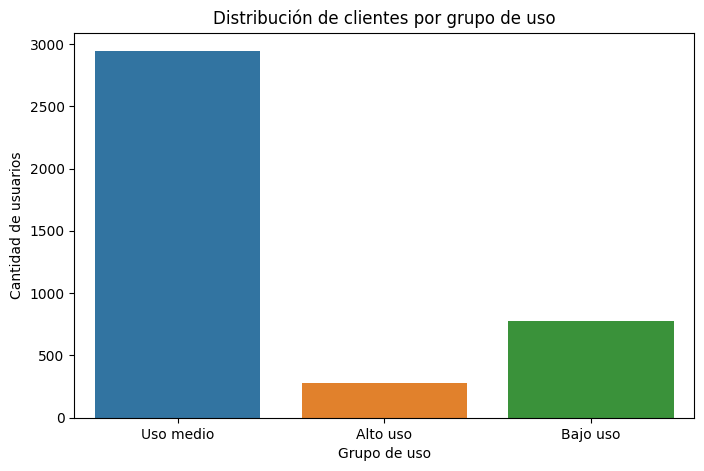

In [ ]:
# Visualización de los segmentos por uso
plt.figure(figsize=(8, 5))

sns.countplot(data=user_profile, x='grupo_uso')

plt.title('Distribución de clientes por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')

plt.show()

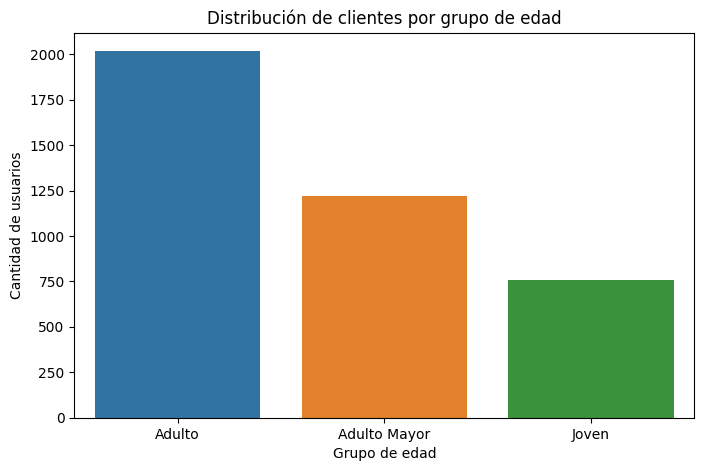

In [ ]:
# Visualización de los segmentos por edad
plt.figure(figsize=(8, 5))

sns.countplot(data=user_profile, x='grupo_edad')

plt.title('Distribución de clientes por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')

plt.show()


<div class="alert alert-block alert-success">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a><br>
<b>Éxito ✅</b><br>
La segmentación por uso y edad está correctamente planteada y las visualizaciones permiten entender con facilidad el tamaño de cada grupo. Es positivo que uses reglas simples y comprensibles para clasificar a los clientes en Bajo, Medio y Alto uso, así como Joven, Adulto y Adulto Mayor.
</div>



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- `age` (users): 55 registros (1.4% de las 4,000 filas) tenían el sentinel -999, que distorsionaba la media (33.7 frente a una mediana de 48) y la desviación estándar (123.2). Se reemplazó por la mediana.
- `city` (users): 96 valores "?" (2.4%) sumados a 469 nulos, 565 en total (14.1%). Se dejaron como nulos.
- `reg_date` (users): 40 registros (1.0%) con año 2026, imposible porque los datos llegan hasta 2024. Se marcaron como nulos.
- `duration` y `length` (usage): 22,076 (55.2%) y 17,896 (44.7%) nulos. Son MAR: dependen de `type` (99.9% de nulos donde el campo no aplica y 0% donde sí), así que se dejaron como nulos.
- `date` (usage): 50 nulos (0.125%) y todas las demás fechas son de 2024.
- `churn_date` (users): 88.4% de nulos, que corresponde a clientes activos, no a un error. Las 466 bajas representan el 11.65% de la base.

🔍 **Segmentos por Edad**
- Las edades van de 18 a 79 años (mediana 48) y se reparten de forma casi uniforme, sin outliers. Basico (64.9%) y Premium (35.1%) tienen la misma distribución de edad: la edad no distingue a un plan del otro.
- Los grupos (Joven <30, Adulto <60, Adulto Mayor desde 60) tienen tamaños proporcionales a la amplitud de su rango. Adulto (30 a 59 años) es el más grande y Joven el más pequeño.

📊 **Segmentos por Nivel de Uso**
- Uso medio: 2,943 usuarios (73.6%). Bajo uso: 778 (19.5%). Alto uso: 279 (7.0%).
- Mensajes y llamadas tienen forma de campana con sesgo leve a la derecha: la mayoría envía entre 4 y 7 mensajes y hace entre 3 y 6 llamadas. Los minutos de llamada están más sesgados (mediana 19.8, media 23.3).
- Basico y Premium se comportan igual: la distribución de mensajes, llamadas y minutos es la misma en ambos planes.
- Valores extremos: hasta 17 mensajes (límite IQR 11.5), 15 llamadas (límite 10.5) y 155.7 minutos (límite 61.9, casi 8 veces la mediana). Solo hay outliers por arriba y se mantienen, porque parecen usuarios muy activos y no errores.

➡️ Esto sugiere que el plan contratado no explica el consumo: Premium cuesta USD 25 frente a USD 12 de Basico y ofrece 500 mensajes y 600 minutos incluidos contra 100 y 100, pero ni siquiera los usuarios más intensos se acercan a esos límites en los datos de uso. El plan Premium parece sobredimensionado respecto al uso de llamadas y mensajes, y el consumo de datos (GB) no está en `usage`, así que no se puede evaluar.

💡 **Recomendaciones**
- Revisar la propuesta de valor de Premium (35.1% de la base): su uso de llamadas y mensajes es igual al de Basico. Replantear sus beneficios hacia lo que sí lo diferencia (por ejemplo GB u otros servicios) o ajustar su precio, y validar con datos de GB antes de decidir.
- Diseñar ofertas por nivel de uso: un plan más económico o de pago por uso para el segmento de Bajo uso (19.5%), y una oferta específica o fidelización para el de Alto uso (7.0%), que concentra a los usuarios con más valor potencial y los outliers.
- Analizar el churn (11.65%) por plan y por grupo de uso para identificar qué segmentos se están perdiendo, y revisar los outliers extremos por si hay errores de registro o fraude.
- Mejorar la captura de datos: validar `age`, `city` y `reg_date` al registrar para evitar sentinels, "?" y años imposibles.

<div class="alert alert-block alert-success">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a><br>
<b>Éxito ✅</b><br>
Muy buen insight ejecutivo. Integras problemas de calidad, comportamiento por plan, segmentos y valores extremos, y traduces esos hallazgos en recomendaciones de negocio. Destaco especialmente que señalas la limitación de no contar con consumo de GB antes de concluir sobre la propuesta de valor de Premium; eso demuestra una interpretación responsable de los datos.
</div>


---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`

<div class="alert alert-block alert-warning">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a><br>
<b>Atención ⚠️</b><br>
El repositorio público es accesible y contiene README y notebooks, por lo que el entregable puede revisarse. El README también explica objetivo, datasets, metodología, hallazgos y cómo ejecutar el proyecto. Como mejora de trazabilidad, procura que la estructura real del repositorio coincida con la estructura descrita en el README: allí indicas una carpeta <code>notebooks/</code>, pero actualmente los notebooks están en la raíz. También reemplaza el placeholder <code>LINK a tu repo aquí</code> dentro del notebook por el enlace real en formato Markdown.
</div>
